# ⚡ Electricity Demand Forecasting for the Power Grid
**NextGen Institute · Machine Learning · Final Project 15** — Energy · Utilities · Regression (time series)

**Dataset:** PJM East hourly demand (`PJME_hourly.csv`) — [Kaggle: robikscube/hourly-energy-consumption](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption)

| Step | Content |
|---|---|
| 1 | Problem framing |
| 2 | Data understanding |
| 3 | EDA |
| 4 | Preprocessing & feature engineering (no leakage) |
| 5 | Modeling (baseline + 3 algorithms) |
| 6 | Tuning & time-series cross-validation |
| 7 | Evaluation & error analysis |
| 8 | Business insights |
| 9 | Save pipeline for the Streamlit app |

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

RANDOM_STATE = 42
CV_SPLITS = 5          # TimeSeriesSplit folds
N_ITER_RF = 8          # random-search iterations (lower = faster)
N_ITER_LGBM = 20

ROOT = Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "PJME_hourly.csv"
PROC_DIR = ROOT / "data" / "processed"
APP_DIR = ROOT / "app"
sys.path.insert(0, str(APP_DIR))
from features import TARGET, FEATURES, make_features, forecast   # shared with the Streamlit app

def mape(y, p):
    return mean_absolute_percentage_error(y, p) * 100

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

## Step 1 · Problem Framing

| Item | Definition |
|---|---|
| **Who has the problem?** | Grid operators / system planners at a power company (here: PJM East region, U.S.). |
| **Decision supported** | Day-ahead planning: how much generation to schedule for each hour of tomorrow, and when to prepare reserves or demand response. |
| **Why it matters** | **Under-forecasting** → shortages, blackouts and load shedding. **Over-forecasting** → wasted fuel, higher cost and emissions. |
| **Target variable** | `PJME_MW` — hourly electricity demand in megawatts. |
| **Business metric** | **MAPE** (error as % of demand — easy for managers to read and comparable across periods). **RMSE** (in MW) is the secondary metric because it punishes large misses, which are the dangerous ones. |
| **Validation rule** | Time-based split only. The model may never see the future. |

**Forecast horizon:** all features are available at 23:00 of the previous day (day-ahead forecast).

## Step 2 · Data Understanding

**Column dictionary**

| Column | Type | Meaning |
|---|---|---|
| `Datetime` | datetime | Timestamp of the hourly reading (local time) |
| `PJME_MW` | float | Electricity demand of PJM East in megawatts (MW) |

In [2]:
raw = pd.read_csv(RAW_PATH, parse_dates=["Datetime"])
print("Shape:", raw.shape)
print("Date range:", raw["Datetime"].min(), "→", raw["Datetime"].max())
display(raw.head())
display(raw.dtypes.to_frame("dtype"))
display(raw.isna().sum().to_frame("missing values"))
display(raw[TARGET].describe().to_frame().T)

Shape: (145366, 2)
Date range: 2002-01-01 01:00:00 → 2018-08-03 00:00:00


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


,dtype
Datetime,datetime64[us]
PJME_MW,float64


,missing values
Datetime,0
PJME_MW,0


,count,mean,std,min,25%,50%,75%,max
PJME_MW,145366.0,32080.222831,6464.012166,14544.0,27573.0,31421.0,35650.0,62009.0


In [3]:
# Data-quality checks: duplicated timestamps (daylight-saving "fall back" hour) and hourly frequency
n_dup = raw["Datetime"].duplicated().sum()
print("Duplicated timestamps:", n_dup)

s = raw.set_index("Datetime").sort_index()[TARGET]
s = s.groupby(level=0).mean()               # average duplicated timestamps

full = s.asfreq("h")                        # force a regular hourly grid -> missing hours appear as NaN
n_missing = int(full.isna().sum())
print(f"Rows: {len(s):,} | Expected hourly rows: {len(full):,} | Missing hours: {n_missing}")
print("Longest gap (hours):", int(full.isna().astype(int).groupby(full.notna().cumsum()).sum().max()))

full = full.interpolate(method="time")      # short gaps -> time interpolation

# the raw file ends with a single reading of a partial day -> keep complete days only
full = full.loc[: full.index[-1].normalize() - pd.Timedelta(hours=1)]
assert full.isna().sum() == 0 and full.index.freq is not None and full.index[-1].hour == 23
full.name = TARGET

PROC_DIR.mkdir(parents=True, exist_ok=True)
full.to_frame().to_csv(PROC_DIR / "pjme_hourly_clean.csv")
print("Clean series saved. Shape:", full.shape)

Duplicated timestamps: 4
Rows: 145,362 | Expected hourly rows: 145,392 | Missing hours: 30
Longest gap (hours): 1
Clean series saved. Shape: (145391,)


**Findings:** the series is hourly, spans more than 10 years, has a few duplicated timestamps (daylight-saving time) and a small number of missing hours.
We averaged duplicates, forced a regular hourly grid with `.asfreq('h')` and filled the short gaps with time interpolation (needed because lag features assume exactly one row per hour).

## Step 3 · Exploratory Data Analysis

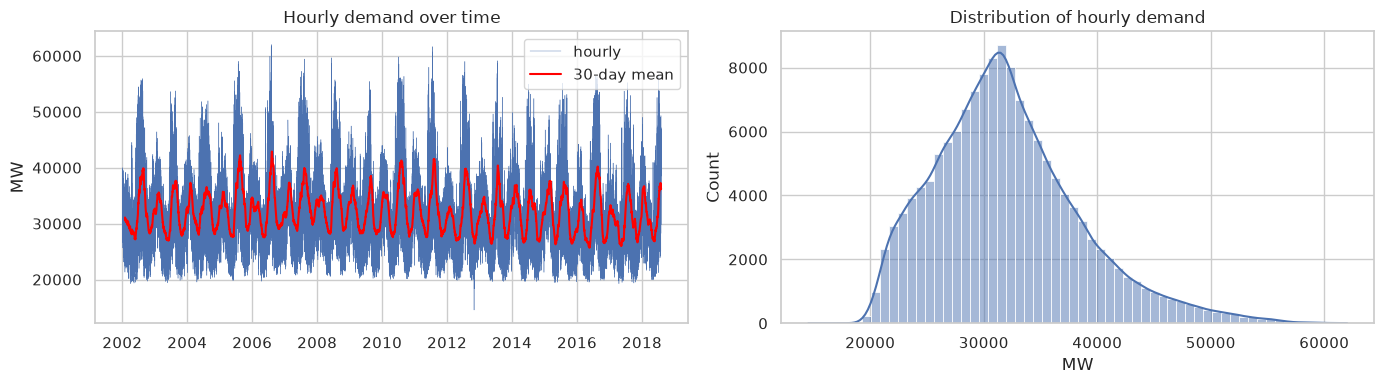

In [4]:
eda = full.to_frame()
eda["hour"] = eda.index.hour
eda["dayofweek"] = eda.index.dayofweek
eda["month"] = eda.index.month
eda["year"] = eda.index.year

# --- Univariate
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(full.index, full.values, lw=0.3, label="hourly")
ax[0].plot(full.rolling(24 * 30).mean(), color="red", lw=1.5, label="30-day mean")
ax[0].set_title("Hourly demand over time"); ax[0].set_ylabel("MW"); ax[0].legend()
sns.histplot(full, bins=60, kde=True, ax=ax[1])
ax[1].set_title("Distribution of hourly demand"); ax[1].set_xlabel("MW")
plt.tight_layout(); plt.show()

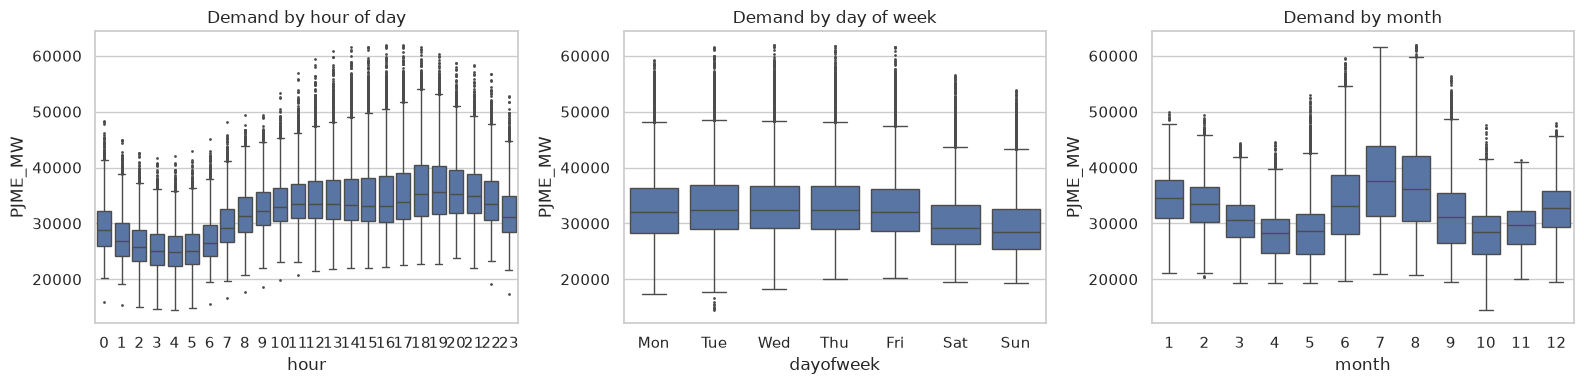

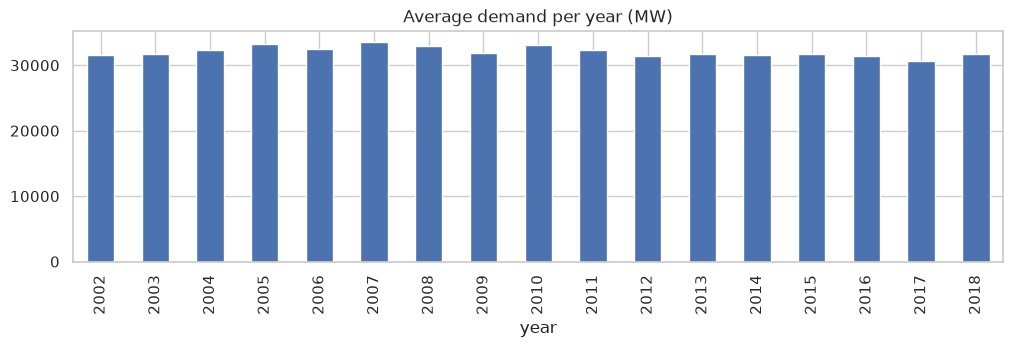

In [5]:
# --- Bivariate: demand vs hour / day of week / month
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=eda, x="hour", y=TARGET, ax=ax[0], fliersize=1); ax[0].set_title("Demand by hour of day")
sns.boxplot(data=eda, x="dayofweek", y=TARGET, ax=ax[1], fliersize=1)
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]); ax[1].set_title("Demand by day of week")
sns.boxplot(data=eda, x="month", y=TARGET, ax=ax[2], fliersize=1); ax[2].set_title("Demand by month")
plt.tight_layout(); plt.show()

yearly = eda.groupby("year")[TARGET].mean()
yearly.plot(kind="bar", figsize=(12, 3), title="Average demand per year (MW)"); plt.show()

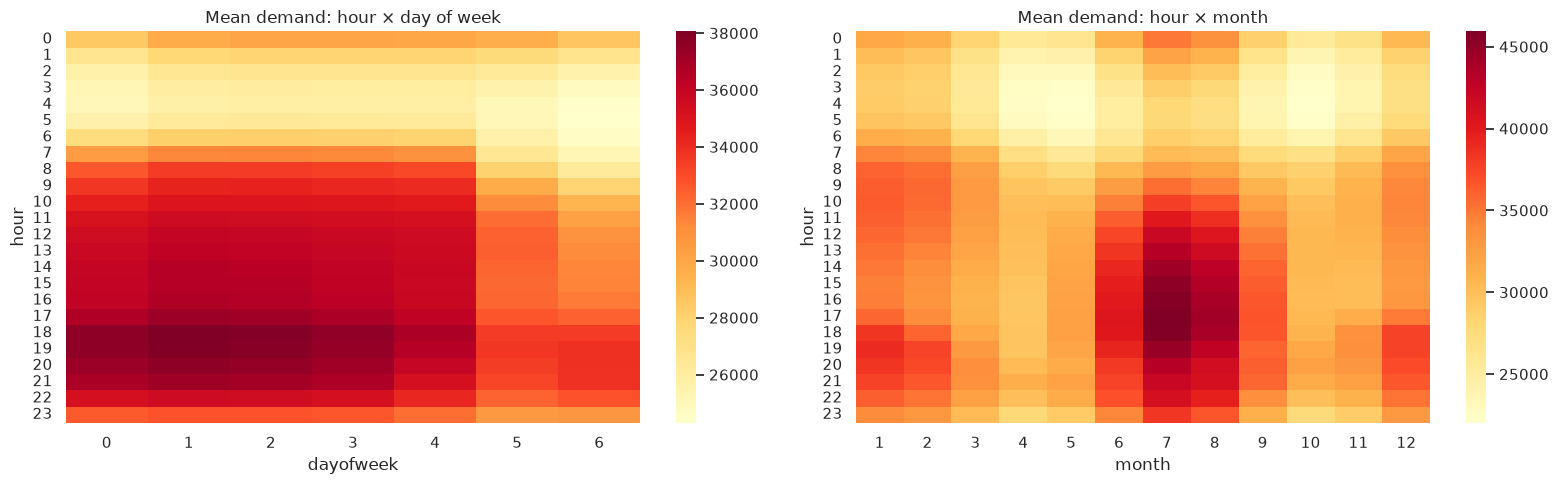

,autocorrelation
1,0.975
24,0.891
48,0.773
72,0.721
168,0.782
336,0.746


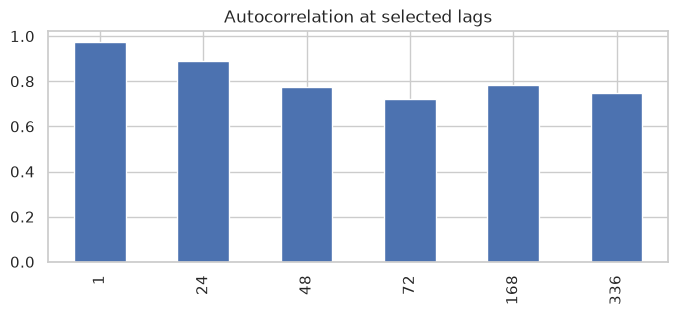

In [6]:
# --- Multivariate: hour x weekday and hour x month interactions, plus autocorrelation
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(eda.pivot_table(index="hour", columns="dayofweek", values=TARGET, aggfunc="mean"), cmap="YlOrRd", ax=ax[0])
ax[0].set_title("Mean demand: hour × day of week")
sns.heatmap(eda.pivot_table(index="hour", columns="month", values=TARGET, aggfunc="mean"), cmap="YlOrRd", ax=ax[1])
ax[1].set_title("Mean demand: hour × month")
plt.tight_layout(); plt.show()

acf = pd.Series({lag: full.autocorr(lag) for lag in [1, 24, 48, 72, 168, 336]}, name="autocorrelation")
display(acf.round(3).to_frame())
acf.plot(kind="bar", figsize=(8, 3), title="Autocorrelation at selected lags"); plt.show()

### EDA insights / hypotheses
1. **Strong daily cycle:** demand is lowest at night and peaks in the afternoon/evening → `hour` (and its sin/cos encoding) must be a feature.
2. **Weekly pattern:** weekends are clearly lower than weekdays → `dayofweek` / `is_weekend`; and the hour × weekday heatmap shows the *shape* of the day changes between weekdays and weekends.
3. **Two seasons of stress:** summer (air-conditioning) and winter (heating) are higher than spring/autumn → `month`, `dayofyear`.
4. **Very high autocorrelation at lags 24 and 168:** the same hour yesterday / last week is a strong predictor → lag features and a simple "yesterday" baseline will already be hard to beat.
5. **No big long-run trend:** yearly averages move only slightly, so a model trained on the past should transfer to the future — but holidays and heat waves will create outliers.

## Step 4 · Preprocessing & Feature Engineering (no leakage)

Features (all implemented in `app/features.py` so the notebook and the Streamlit app use **identical** code):

| Group | Features |
|---|---|
| Calendar | `hour, dayofweek, month, year, quarter, dayofyear` (+ `is_weekend`, `is_holiday` extras) |
| Cyclical | `sin_hour, cos_hour` |
| Lags | `lag_24, lag_48, lag_168` |
| Rolling | `rolling_mean_24, rolling_std_24` — computed on the series **shifted by 24 h**, so they only use data known at day-ahead time |

**Leakage rules:** (1) every lag/rolling value uses only the past; (2) the split is chronological; (3) the scaler lives inside the sklearn `Pipeline`, so it is fitted on training folds only.

In [7]:
data = make_features(full).dropna()          # first 7 days drop out (no lag_168 yet)
X, y = data[FEATURES], data[TARGET]

SPLIT_DATE = "2017-01-01"                    # Train: 2002–2016 | Test: 2017 → end of data
train_mask = data.index < SPLIT_DATE
X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[~train_mask], y[~train_mask]

print(f"Train: {X_train.index.min():%Y-%m-%d} → {X_train.index.max():%Y-%m-%d}  ({len(X_train):,} rows)")
print(f"Test : {X_test.index.min():%Y-%m-%d} → {X_test.index.max():%Y-%m-%d}  ({len(X_test):,} rows)")
assert X_train.index.max() < X_test.index.min()      # chronological, no overlap
display(X_train.head(3))

Train: 2002-01-08 → 2016-12-31  (131,327 rows)
Test : 2017-01-01 → 2018-08-02  (13,896 rows)


,hour,dayofweek,month,year,quarter,dayofyear,is_weekend,is_holiday,sin_hour,cos_hour,lag_24,lag_48,lag_168,rolling_mean_24,rolling_std_24
Datetime,,,,,,,,,,,,,,,
2002-01-08 01:00:00,1,1,1,2002,1,8,0,0,0.258819,0.965926,26862.0,27100.0,30393.0,30285.583333,3345.031122
2002-01-08 02:00:00,2,1,1,2002,1,8,0,0,0.500000,0.866025,25976.0,26097.0,29265.0,30280.541667,3351.703214
2002-01-08 03:00:00,3,1,1,2002,1,8,0,0,0.707107,0.707107,25641.0,25793.0,28357.0,30274.208333,3360.683070


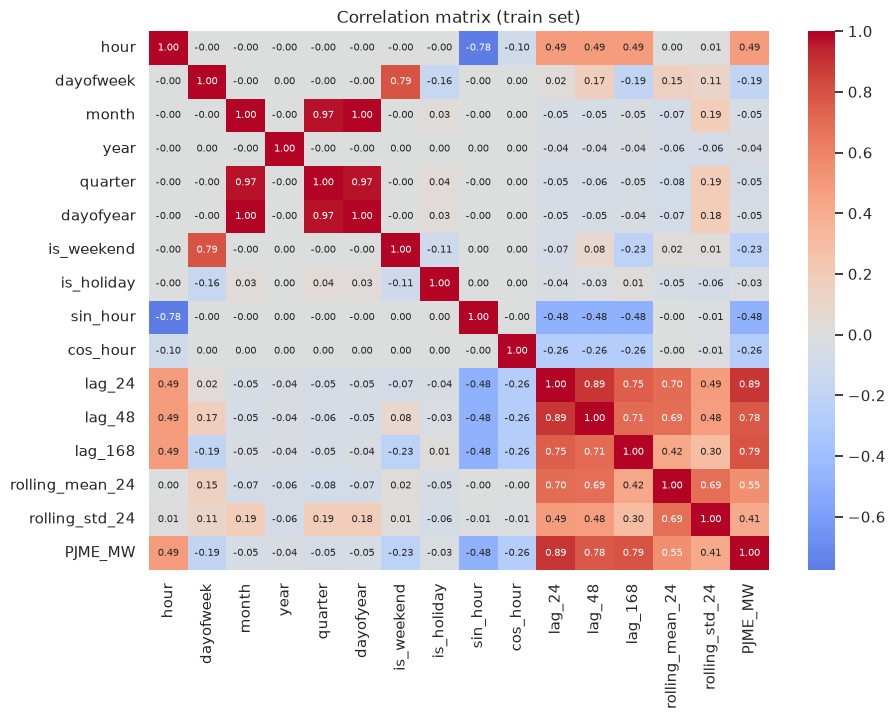

In [8]:
# Multivariate check on TRAIN only: correlation of features with the target
corr = pd.concat([X_train, y_train], axis=1).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix (train set)"); plt.show()

## Step 5 · Modeling

* **Baseline:** "same hour yesterday" (`lag_24`) — what an operator could do with no ML.
* **Models:** Ridge Regression (linear), Random Forest, LightGBM (gradient boosting).

Models are compared with **`TimeSeriesSplit` cross-validation on the training set only** — the test set stays untouched until Step 7.

In [9]:
tscv = TimeSeriesSplit(n_splits=CV_SPLITS)
SCORING = {"mape": "neg_mean_absolute_percentage_error", "rmse": "neg_root_mean_squared_error"}

# In Step 5 (Models configuration)
models = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(random_state=RANDOM_STATE)),
    ]),
    "RandomForest": Pipeline([(
        "model",
        RandomForestRegressor(
            n_estimators=50,
            min_samples_leaf=10,
            n_jobs=1,
            random_state=RANDOM_STATE,
        ),
    )]),
    "LightGBM": Pipeline([(
        "model",
        LGBMRegressor(
            n_jobs=1, verbose=-1, random_state=RANDOM_STATE
        ),
    )]),
}

rows = []
# baseline: predict lag_24 for each validation fold
b_mape, b_rmse = [], []
for _, val_idx in tscv.split(X_train):
    b_mape.append(mape(y_train.iloc[val_idx], X_train["lag_24"].iloc[val_idx]))
    b_rmse.append(rmse(y_train.iloc[val_idx], X_train["lag_24"].iloc[val_idx]))
rows.append({"Model": "Baseline (lag_24)", "CV MAPE %": np.mean(b_mape), "CV RMSE MW": np.mean(b_rmse)})

for name, pipe in models.items():
    t0 = time.time()
    cv = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=SCORING, n_jobs=1)
    rows.append({"Model": name, "CV MAPE %": -cv["test_mape"].mean() * 100, "CV RMSE MW": -cv["test_rmse"].mean()})
    print(f"{name:13s} done in {time.time() - t0:5.1f}s")

cv_default = pd.DataFrame(rows).set_index("Model").round(2)
display(cv_default)

Ridge         done in   1.3s
RandomForest  done in 366.3s
LightGBM      done in  11.3s


,CV MAPE %,CV RMSE MW
Model,,
Baseline (lag_24),6.56,2971.43
Ridge,5.70,2445.60
RandomForest,4.87,2247.63
LightGBM,5.10,2310.67


## Step 6 · Hyperparameter Tuning & Validation

`GridSearchCV` (Ridge) and `RandomizedSearchCV` (Random Forest, LightGBM) using **`TimeSeriesSplit`** — each validation fold is always *after* its training fold. Only the training set is used.

In [10]:
# In Step 6 (Hyperparameter tuning)
searches = {
    "Ridge": GridSearchCV(
        models["Ridge"],
        {"model__alpha": [0.1, 1, 10, 100]},
        cv=tscv,
        scoring="neg_mean_absolute_percentage_error",
        n_jobs=1,
    ),
    "RandomForest": RandomizedSearchCV(
        models["RandomForest"],
        {
            "model__n_estimators": [50, 100],
            "model__max_depth": [10, 20],
            "model__min_samples_leaf": [5, 10],
        },
        n_iter=3,
        cv=tscv,
        scoring="neg_mean_absolute_percentage_error",
        n_jobs=1,
        random_state=RANDOM_STATE,
    ),
    "LightGBM": RandomizedSearchCV(
        models["LightGBM"],
        {
            "model__n_estimators": [100, 300],
            "model__learning_rate": [0.03, 0.1],
            "model__num_leaves": [31, 63],
        },
        n_iter=5,
        cv=tscv,
        scoring="neg_mean_absolute_percentage_error",
        n_jobs=1,
        random_state=RANDOM_STATE,
    ),
}

for name, search in searches.items():
    t0 = time.time()
    search.fit(X_train, y_train)
    print(f"{name:13s} best CV MAPE = {-search.best_score_ * 100:.2f}%  ({time.time() - t0:.0f}s)")
    print("   best params:", search.best_params_)

Ridge         best CV MAPE = 5.70%  (4s)
   best params: {'model__alpha': 100}
RandomForest  best CV MAPE = 4.90%  (1812s)
   best params: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_depth': 20}
LightGBM      best CV MAPE = 5.03%  (122s)
   best params: {'model__num_leaves': 31, 'model__n_estimators': 300, 'model__learning_rate': 0.03}


## Step 7 · Evaluation & Error Analysis (untouched test set)

In [11]:
results, test_pred = [], {}

# 1. Baseline prediction
test_pred["Baseline (lag_24)"] = X_test["lag_24"].values

# 2. Predict using best estimators sequentially (n_jobs=1)
for name, search in searches.items():
  print(f"Generating predictions for {name}...")
  test_pred[name] = search.best_estimator_.predict(X_test)

# Calculate metrics
for name, p in test_pred.items():
  results.append({
      "Model": name,
      "MAPE %": mape(y_test, p),
      "RMSE MW": rmse(y_test, p),
  })

results_df = pd.DataFrame(results).set_index("Model").round(2)
display(results_df)

tuned = results_df.drop(index="Baseline (lag_24)")
best_name = tuned["MAPE %"].idxmin()
best_pred = pd.Series(test_pred[best_name], index=y_test.index)
gain = (
    1
    - results_df.loc[best_name, "MAPE %"]
    / results_df.loc["Baseline (lag_24)", "MAPE %"]
) * 100
print(
    f"\n🏆 Best model: {best_name} — MAPE {results_df.loc[best_name, 'MAPE %']:.2f}%"
    f" ({gain:.0f}% lower error than the baseline)"
)

Generating predictions for Ridge...
Generating predictions for RandomForest...
Generating predictions for LightGBM...


,MAPE %,RMSE MW
Model,,
Baseline (lag_24),7.32,3134.26
Ridge,6.60,2716.48
RandomForest,5.95,2579.07
LightGBM,5.93,2514.13



🏆 Best model: LightGBM — MAPE 5.93% (19% lower error than the baseline)


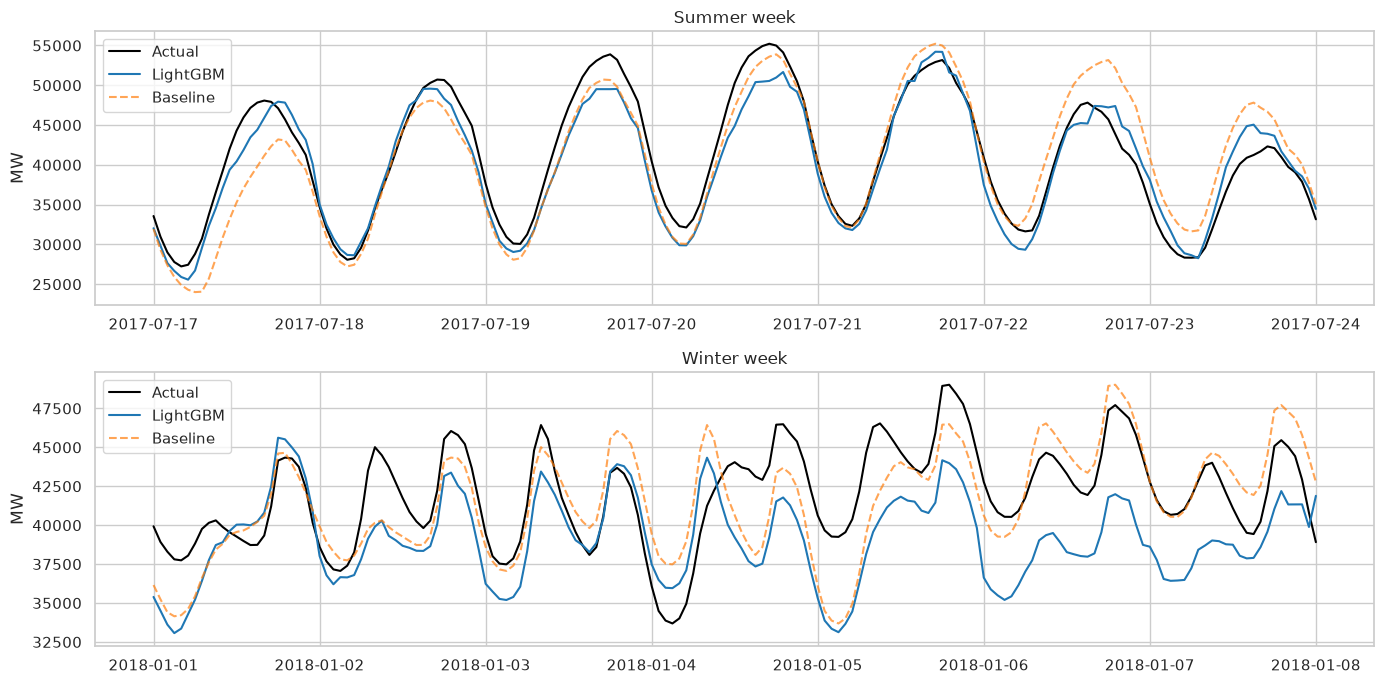

In [12]:
# Actual vs predicted: one summer week and one winter week of the test period
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
for a, (start, label) in zip(ax, [("2017-07-17", "Summer week"), ("2018-01-01", "Winter week")]):
    end = pd.Timestamp(start) + pd.Timedelta(days=7)
    a.plot(y_test[start:end], label="Actual", color="black")
    a.plot(best_pred[start:end], label=f"{best_name}", color="tab:blue")
    a.plot(X_test["lag_24"][start:end], label="Baseline", color="tab:orange", ls="--", alpha=0.7)
    a.set_title(label); a.set_ylabel("MW"); a.legend()
plt.tight_layout(); plt.show()

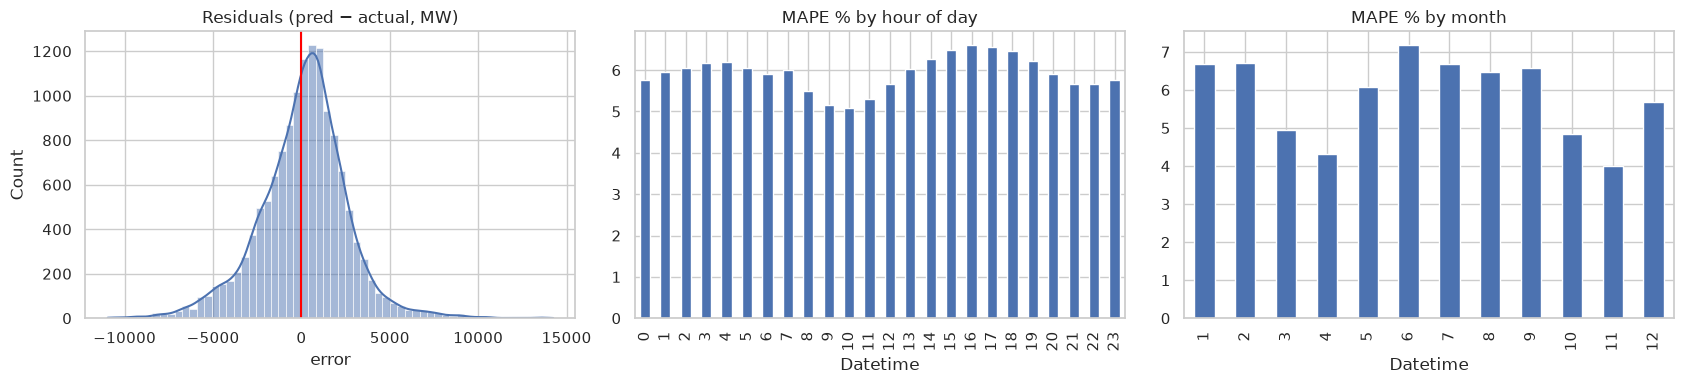

,MAPE,RMSE,bias_MW,under_forecast_share
Normal hours,5.81,2348.20,311.71,41.85
"Peak hours (≥ 40,705 MW)",7.34,3958.45,-2105.34,72.10


5 worst days (daily MAPE %):


,MAPE %
2017-05-20,25.17
2018-07-07,24.83
2018-05-28,20.32
2018-06-03,18.74
2017-09-01,18.01


In [13]:
# Error analysis
err = pd.DataFrame({"actual": y_test, "pred": best_pred})
err["error"] = err["pred"] - err["actual"]                      # >0 = over-forecast, <0 = under-forecast
err["abs_pct"] = err["error"].abs() / err["actual"] * 100

peak_threshold = y_train.quantile(0.90)                         # "peak" defined from TRAIN data only
err["is_peak"] = err["actual"] >= peak_threshold

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(err["error"], bins=60, kde=True, ax=ax[0]); ax[0].axvline(0, color="red")
ax[0].set_title("Residuals (pred − actual, MW)")
err.groupby(err.index.hour)["abs_pct"].mean().plot(kind="bar", ax=ax[1], title="MAPE % by hour of day")
err.groupby(err.index.month)["abs_pct"].mean().plot(kind="bar", ax=ax[2], title="MAPE % by month")
plt.tight_layout(); plt.show()

peak_stats = err.groupby("is_peak").agg(MAPE=("abs_pct", "mean"),
                                        RMSE=("error", lambda e: np.sqrt((e ** 2).mean())),
                                        bias_MW=("error", "mean"),
                                        under_forecast_share=("error", lambda e: (e < 0).mean() * 100))
peak_stats.index = ["Normal hours", f"Peak hours (≥ {peak_threshold:,.0f} MW)"]
display(peak_stats.round(2))

print("5 worst days (daily MAPE %):")
display(err.groupby(err.index.date)["abs_pct"].mean().nlargest(5).round(2).to_frame("MAPE %"))

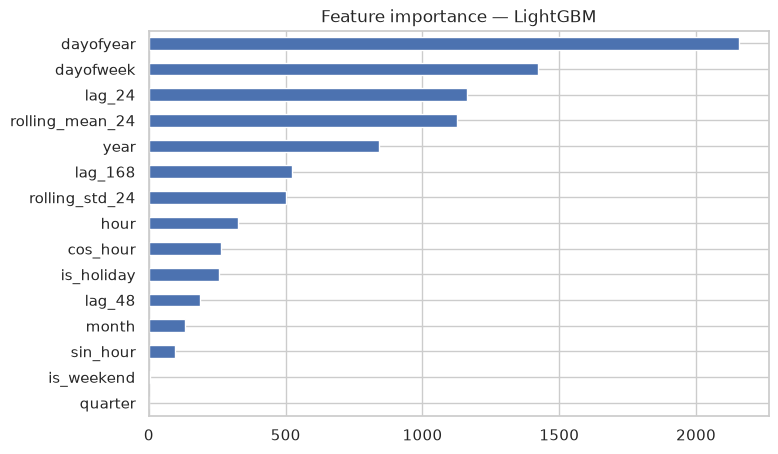

In [14]:
# Feature importance of the best model (if it exposes one)
est = searches[best_name].best_estimator_.named_steps["model"]
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind="barh", figsize=(8, 5), title=f"Feature importance — {best_name}"); plt.show()
elif hasattr(est, "coef_"):
    coef = pd.Series(est.coef_, index=FEATURES).sort_values()
    coef.plot(kind="barh", figsize=(8, 5), title="Standardised Ridge coefficients"); plt.show()

## Step 8 · Business Insights

In [15]:
peak_row = peak_stats.iloc[1]
worst_hour = err.groupby(err.index.hour)["abs_pct"].mean().idxmax()
b_mape_t = results_df.loc["Baseline (lag_24)", "MAPE %"]
best_mape = results_df.loc[best_name, "MAPE %"]
best_rmse = results_df.loc[best_name, "RMSE MW"]
print("SUMMARY (all numbers computed above)")
print(f"- Best model: {best_name} - MAPE {best_mape:.2f}%, RMSE {best_rmse:.0f} MW on the untouched test set.")
print(f"- Baseline 'same hour yesterday': MAPE {b_mape_t:.2f}%  ->  ML cuts the error by {gain:.0f}%.")
print(f"- Peak hours: MAPE {peak_row['MAPE']:.2f}%, average bias {peak_row['bias_MW']:.0f} MW, "
      f"under-forecast in {peak_row['under_forecast_share']:.0f}% of peak hours.")
print(f"- Hardest hour of the day to forecast: {worst_hour}:00.")

SUMMARY (all numbers computed above)
- Best model: LightGBM - MAPE 5.93%, RMSE 2514 MW on the untouched test set.
- Baseline 'same hour yesterday': MAPE 7.32%  ->  ML cuts the error by 19%.
- Peak hours: MAPE 7.34%, average bias -2105 MW, under-forecast in 72% of peak hours.
- Hardest hour of the day to forecast: 16:00.


### Recommendations for grid managers
1. **Use the model as the day-ahead starting point** and replace the "same hour yesterday" rule — see the error reduction above.
2. **Plan reserves around the peak hours:** peaks are the costly hours. Check the peak bias above: if the model under-forecasts peaks on average, add a safety margin (e.g. schedule reserve equal to the peak RMSE) rather than trusting the point forecast.
3. **Pay extra attention to holidays, heat waves and cold snaps** — the "worst days" table shows where errors are largest; flag such days for manual review.
4. **Use the capacity warning in the dashboard** as an early-warning tool: when forecast demand approaches the limit, trigger demand-response or reserve generation the day before, not the same afternoon.

### Limitations
* **No weather data** (temperature is the biggest missing driver of demand); adding it would likely reduce error on extreme days.
* Trained on **2002–2018 PJM East** data; behaviour changed since (rooftop solar, EVs, remote work), so retraining on fresh data is required.
* Multi-day-ahead forecasts in the app are **recursive** (predictions feed later predictions) and become less reliable with each day.
* Rare events (storms, blackouts, pandemic shocks) are not predictable from calendar and lag features alone.
* Point forecasts only — no prediction intervals.

## Step 9 · Save the Final Pipeline for the Web App

The deployed model is the best tuned pipeline **re-fitted on all available data** (train + test) so it has seen the most recent behaviour. The honest performance numbers are the test-set scores from Step 7 (model trained only on ≤ 2016).

The saved bundle also contains the demand history, which the app needs to build lag features.

In [17]:
final_model = clone(searches[best_name].best_estimator_).fit(X, y)       # refit on all data

history = full.copy()     # complete days only (trimmed in Step 2) -> ends at 23:00

APP_DIR.mkdir(parents=True, exist_ok=True)

bundle = {
    "model": final_model,
    "model_name": best_name,
    "history": history,
    "features": FEATURES,
    "metrics": {"MAPE": float(results_df.loc[best_name, "MAPE %"]),
                "RMSE": float(results_df.loc[best_name, "RMSE MW"])},
    "trained_until": str(history.index[-1]),
}
joblib.dump(bundle, APP_DIR / "model.joblib", compress=3)
print("Saved", APP_DIR / "model.joblib", f"({(APP_DIR / 'model.joblib').stat().st_size / 1e6:.1f} MB)")

Saved /home/el-dab3/NextGen/Project/app/model.joblib (2.5 MB)


Forecast for 2017-07-19: peak 50,196 MW at 18:00 | day MAPE 5.39% (in-sample for the refit model)


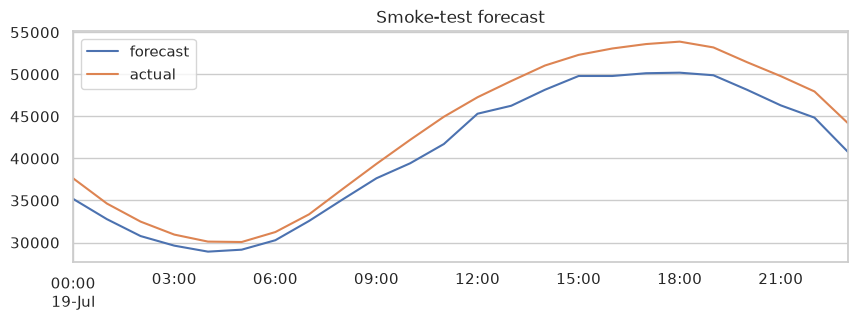

In [18]:
# Smoke test: reload the bundle and forecast one test day exactly as the app will
b = joblib.load(APP_DIR / "model.joblib")
day = pd.Timestamp("2017-07-19")
pred = forecast(b["model"], b["history"], day)
actual = b["history"].reindex(pred.index)
print(f"Forecast for {day.date()}: peak {pred.max():,.0f} MW at {pred.idxmax():%H:%M} | "
      f"day MAPE {((pred - actual).abs() / actual).mean() * 100:.2f}% (in-sample for the refit model)")
pd.DataFrame({"forecast": pred, "actual": actual}).plot(figsize=(10, 3), title="Smoke-test forecast"); plt.show()

**Next:** run the dashboard with `streamlit run app/app.py`, deploy it on Streamlit Community Cloud, then complete the README, presentation and LinkedIn post.